# E120: does fine-tuning on problems the model never solved teach it to solve unseen ones?

*Provisional. Qwen3-1.7B, GSM8K and MATH levels 3-5, 77 problems a pool. Report with every number and its source:
`reports/analyses/2026-11-07_analysis_e120-pass-rate-pools.md`. The decomposition readings of these updates are
qwen-decomp-lead's and are not here.*

## The answer

No. Fine-tuning on the human solutions of 62 problems the model had never solved in 64 samples did not teach it to
solve held-out problems of that kind: 5% and 2.5% of held-out samples were right, all on one problem, against a bar of
10%. It reproduced all 62 training problems. Both fine-tunes damaged the model, and GSM8K accuracy fell from 0.78 to
about half. The pools are 77 a side, under the 100 planned, so all of this is provisional.

"New" here always means "never solved in 64 samples of at most 2,048 tokens", not "absent from the weights".


## What we were trying to test

The project needs two updates of known kind on one real task, to calibrate decomposition readings: one that
strengthens a skill the model already has, and one that teaches something it lacks. We built both from maths
problems.

The unchanged model answered each GSM8K and MATH training problem 16 times without thinking, and 48 more times where
needed. A problem it solved in at least 36 of the 48 fresh samples is **known**. One it never solved in 64 samples is
**new**. Guards removed problems with a likely wrong gold label, problems whose samples were often cut off at the
length cap, and problems too long to train on. Known and new problems were then matched one for one on source, level
and subject. Each pool has 77 problems: 62 for training and 15 held out.

Each pool's 62 problems were used for supervised fine-tuning on their human-written solutions. The recipe is the one
the earlier GSM8K run used on 7,217 problems: 100 steps of 64 sequences. On 62 problems that is 103 passes over each
one. Two seeds per pool change only the order.

At step 100 we read each fine-tune four ways. First, 8 samples per held-out problem of both pools, scored as pass@1,
the share of samples correct averaged over problems. Second, one greedy answer per training problem. Third, the loss
on held-out human solutions. Fourth, greedy accuracy on GSM8K test, against the unchanged model's 0.784. The weight
change was also saved at the steps where its size matches the two updates already read, for qwen-decomp-lead.

## What we expected, and why

- At least 100 problems a pool, since MATH level 5 is hard for a model this size.
- The fine-tune on new problems would memorise its 62 problems and carry little to held-out ones, as fine-tunes on
  invented facts had. We leaned against it reaching 10% held-out pass@1.
- The fine-tune on known problems might leave GSM8K alone, within 0.05 of 0.784. We were unsure, because the same
  recipe on all of GSM8K had dropped it to about 0.6.
- The new pool's update would be larger, since unfamiliar solutions should take a bigger change to fit.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/qwen_pass_pools/figures")


def show(name):
    display(Image(filename=str(FIG / name), width=820))


## What we observed

### Did the fine-tune on new problems learn to solve unseen ones?


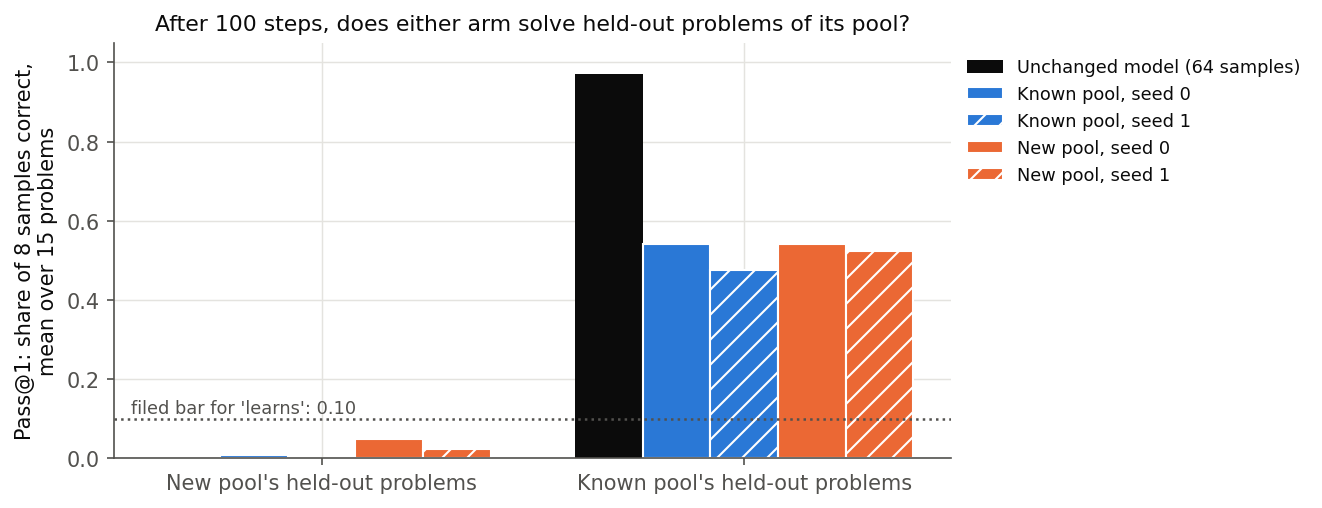

In [2]:
show("pass.png")


**Reading it.** No. On the 15 held-out new problems, the left group, the new-pool fine-tune scores 0.05 and 0.025 in
its two seeds, under the dotted 10% bar. The unchanged model scores 0 there by construction. Every correct sample is
on one GSM8K problem, and read by eye those samples reach the right number by a wrong calculation. The same fine-tune
answers all 62 of its training problems correctly: it memorised them and carries little.

The right group is the surprise. On held-out known problems the unchanged model scores 0.97, and every fine-tune falls
to about half. Fine-tuning on 62 known problems made the model worse at other known problems. Its samples are cut off
at most 4% of the time, so the length cap does not explain this.


### Did either fine-tune leave the rest of the model's maths intact?


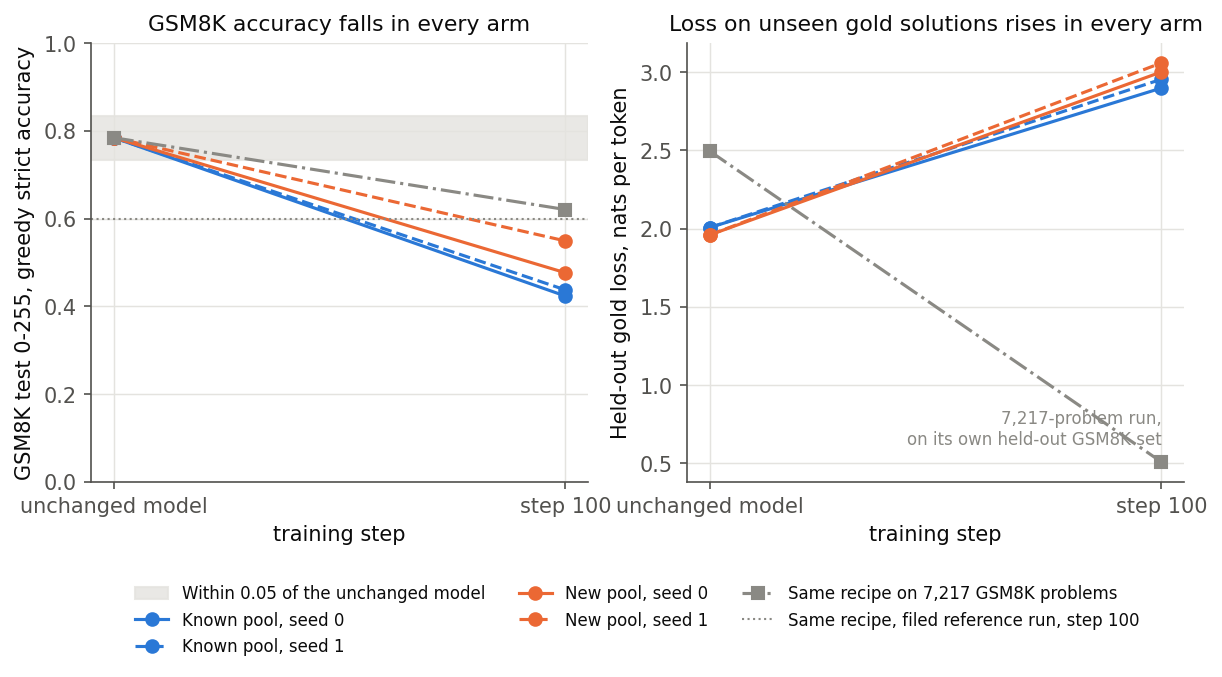

In [3]:
show("damage.png")


**Reading it.** No. On the left, GSM8K test accuracy falls from 0.784 in every fine-tune. The known-pool fine-tune
ends at 0.42 and 0.44, far outside the grey band of 0.05 that the no-damage prediction allowed. The new-pool fine-tune
ends at 0.48 and 0.55. The grey dash-dot line is the same recipe on 7,217 GSM8K problems, which lost less, ending at
0.62.

On the right, loss on held-out human solutions rises in every fine-tune, from about 2.0 to about 3.0 nats per token.
The 7,217-problem run lowered the same kind of loss from 2.5 to 0.5 on its own held-out set.


### How closely did the fine-tunes fit their 62 problems?


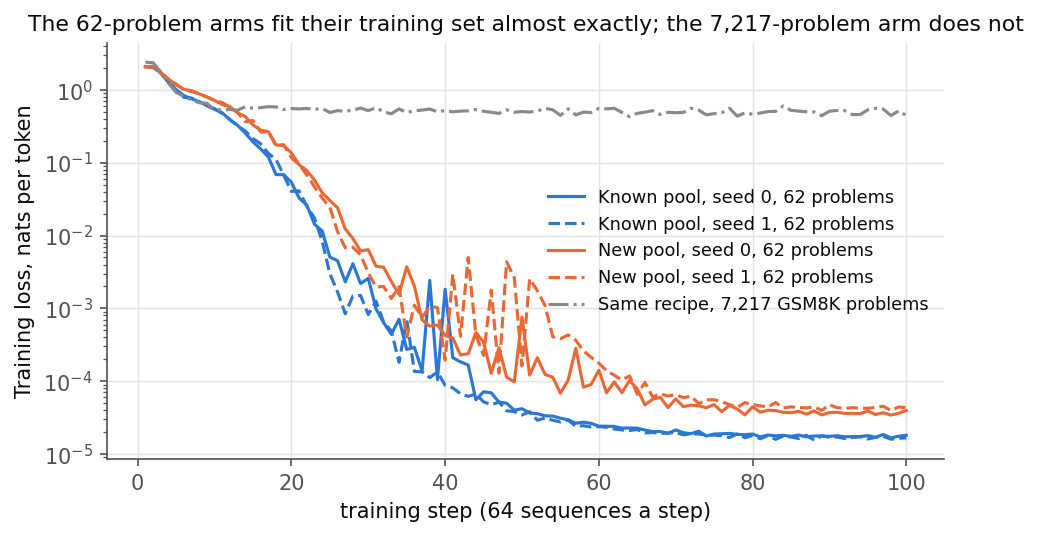

In [4]:
show("fit.png")


**Reading it.** Almost exactly. Training loss first drops below 0.001 between steps 27 and 37, and ends between 0.00002
and 0.00004 nats per token in all four fine-tunes. The 7,217-problem run, which sees each problem less than once, levels off near 0.5. Both pools start at
the same loss, about 2.1, so the known pool's human solutions were no more familiar to the model than the new pool's.

This, the damage above and the rising held-out loss all fit one picture: 103 passes over 62 problems pull the model
towards reciting those 62 solutions. Nothing here rules out other explanations. A run of one or two passes would test
it, and was not run.


### Is the new pool's update larger than the known pool's?


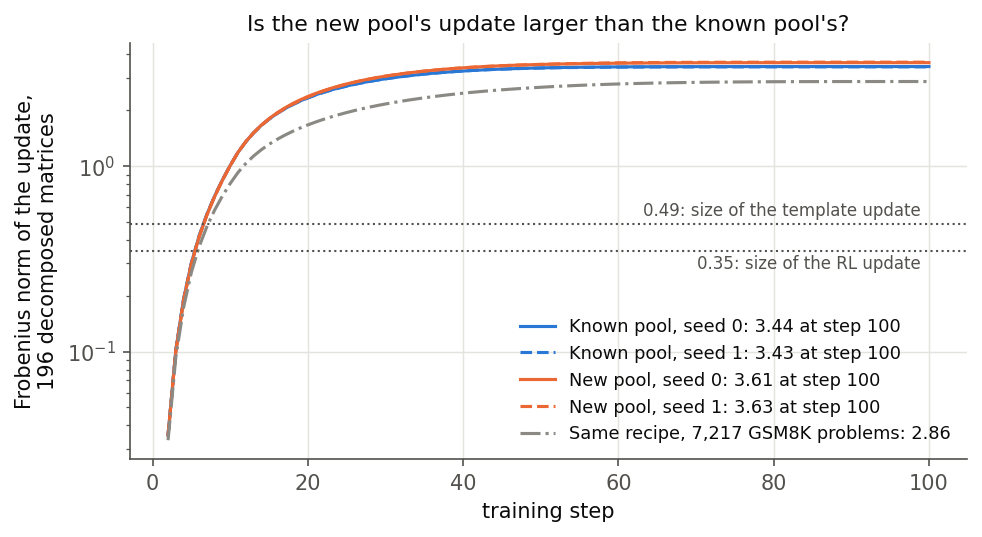

In [5]:
show("size.png")


**Reading it.** Yes, in both seeds, by about 5%. The size here is the Frobenius norm of the weight change over the 196
decomposed matrices. At step 100 the new-pool fine-tunes read 3.61 and 3.63, the known-pool ones 3.44 and 3.43. The
curves overlap until about step 20 and part only as the fit completes. The new pool's training sequences are also
longer, 308 tokens on average against 232, so the gap need not come from what the solutions contain.

All four fine-tunes pass the two sizes already read at the same steps: 0.35, the RL update's size, between steps 5
and 6, and 0.49, the template update's size, between steps 6 and 7. Those saved states are what qwen-decomp-lead
reads.


## What we learned

The model does not learn to solve unseen never-solved problems from 62 human solutions at this recipe; it memorises
the 62. The known-pool fine-tune, meant as the update that strengthens an existing skill, damaged the model as much as
the other. So the two updates differ less in kind than the plan intended. Both are overfit updates on a small set,
and the plainest difference between them is a 5% larger norm that longer solutions could explain. A decomposition
reading that tells them apart is evidence about these two updates, not yet about new skill against existing skill.

## How compelling is the evidence

- Each held-out set is 15 problems with 8 samples each. The new-pool score rests on one problem; one more problem
  solved half the time would have crossed the bar.
- Two seeds per pool, and they agree on every verdict.
- The unchanged model's held-out scores come from 64 samples through a different sampler and length cap. No run
  reads it on the fine-tunes' own path.
- Only step 100 was read for behaviour. The saved states nearest the two sizes, at steps 5 to 7, have no behaviour
  reading.
- With thinking on, the model solved a quarter of the new pool at least once in 4 tries, and almost half its thinking
  samples were cut off. "New" is about no-think answers only.

## Surprises

- The new pool came out at 77, not the 200 to 600 we expected. Fixing the grader did not raise it: a problem the
  grader had wrongly failed is one the model solved, so it leaves the new pool altogether.
- The known-pool fine-tune damaged the model as much as the new-pool one, on held-out known problems and on GSM8K.
- Held-out loss rose in every fine-tune, where the same recipe on all of GSM8K lowered it fivefold.

## What next

- qwen-decomp-lead reads the saved updates under its filed rules, with this caveat attached. A separation at steps 5
  to 7 is the more useful reading, since the damage there is unmeasured.
- Train the same pools for one or two passes and read them the same way. If GSM8K stays near 0.78 and held-out loss
  falls, the damage came from the passes, and the pair should be rebuilt at that length.
- The backup for this anchor, post-cutoff facts, goes ahead.


## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| P1 | new pool has at least 100 problems | 78; 77 after Amendment 2 | missed, stands |
| P2 | at most half the new pool solved with thinking | 0.256; control 0.974 | passes |
| P3 | new-pool fine-tune reaches held-out pass@1 0.10, both seeds | 0.050, 0.025; training greedy 1.0 | no: memorised, carrying little |
| P4 | known-pool fine-tune keeps GSM8K within 0.05 of 0.784 | 0.424, 0.438 | missed, both seeds |
| P5 | new-pool update larger at step 100, both seeds | 3.61 vs 3.44; 3.63 vs 3.43 | holds |

Sources: `pools.json` and `pools_amend2.json` → `meta.n`; `n1.json` → `new.solved_share`, `known.solved_share`;
`grades.json` → `arms.new_s{0,1}.new_held_samples.pass1`; `read_known_s{0,1}.json` →
`step_100.gsm8k.strict_dropped`; `read_<arm>.json` → `files.100.norm`. All under
`experiments/qwen_pass_pools/results/`. No prediction was edited.

## Departures from the literature

- The Qwen3 model card suggests a 32,768-token output budget; we capped MATH at 2,048 tokens when labelling, and the
  fine-tunes' reads at 1,024, for run time.
- MATH answers are graded by math-verify 0.9.0 and, after Amendment 2, also with presentation stripped, which
  math-verify does not do.
- The fine-tuning recipe is the earlier GSM8K run's, unchanged, but on 62 problems instead of 7,217.

## Not run

- Any decomposition reading of these updates: qwen-decomp-lead's.
- Behaviour readings at steps 5, 6, 7 and 10.
- The unchanged model on the fine-tunes' own sampling path.
- The same pools for one or two passes, or 62 random GSM8K problems for 103 passes.
- Thinking-mode samples after fine-tuning.
- An independent check.

## Provenance

MATS cluster `debug` L40, jobs 54969, 55011, 55012, 55013, 33 to 41 min each, $0. Sampling and pools on RunPod, $15.72
in all. Grading on CPU by `experiments/qwen_pass_pools/grade_arms.py`; figures by `experiments/qwen_pass_pools/plot.py`.
